# Callable Bonds: European, Bermudan and American Calls

This notebook prices a **fixed-rate callable bond with issuer default risk** for the three call styles:

| Style | The issuer can redeem the bond at the call price (+ accrued) |
|---|---|
| European | on one date only (end of the call protection) |
| Bermudan | on every coupon date after the call protection (or on any schedule of dates) |
| American | at any time after the call protection, until maturity |

**Model.** Interest rates follow the one-factor **Hull-White** model of `Fixed_Income_Models/hull_white_1F.py`,
fitted exactly to the risk-free curve and calibrated to co-terminal swaptions. Default is a **reduced-form** event:
a deterministic, piecewise constant intensity $\lambda(t)$ bootstrapped from CDS spreads, independent of rates, with
recovery $R$ of par paid at default. The bond value $V(t, x)$ solves

$$
\partial_t V - a x\, \partial_x V + \tfrac12 \sigma^2 \partial_{xx} V - \big(x + \alpha(t) + \lambda(t)\big) V + \lambda(t) R N = 0,
\qquad r(t) = x(t) + \alpha(t),
$$

with $V = N$ at maturity, coupons added on payment dates, and on every call date the **issuer's** choice
$V \leftarrow \min\big(V,\ K(t) + AI(t)\big)$: the issuer redeems when the bond is worth more than the call price.
The three styles only differ by the set of dates where this min is applied. The PDE is solved by Crank-Nicolson
(`Credit_models/callable_bond.py`).

> **What is real and what is assumed.** The risk-free curve is the **ECB euro area AAA government curve** of the
> last date in `Data/EUR` (market data). Swaption volatilities are the **illustrative** EUR grid of
> `Products/rates_market.py` and the issuer CDS spreads are **illustrative** (no free quotes): every price depends on
> these two assumptions.

In [1]:
import os, sys, time
sys.path.append(os.path.abspath(".."))                       # Projets : Fixed_Income_Models package
sys.path.append(os.path.abspath(os.path.join("..", "Products")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

from Fixed_Income_Models import HullWhite, YieldCurve, RatePricer
from rate_products import Swaption
from rates_market import illustrative_swaption_vols
from callable_bond import (CreditCurve, CallableBond, CallableBondPDE, straight_bond_value,
                           european_callable_zero_recovery, option_adjusted_spread, effective_risk, EXERCISE_STYLES)

pd.set_option("display.float_format", lambda x: f"{x:,.6g}")

# Chart style : fixed categorical order, recessive grid and axes, 2px lines
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.prop_cycle": cycler(color=COLORS), "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "lines.linewidth": 2, "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False, "axes.titlesize": 11, "axes.titleweight": "bold"})
STYLE_COLOR = {"straight": MUTED, "european": COLORS[0], "bermudan": COLORS[1], "american": COLORS[2]}

## 1. Risk-free curve

Spot rates of the ECB AAA curve (continuously compounded, 3 months to 30 years), monotone convex interpolation.

Valuation date 2026-10-05 | YieldCurve(name='ECB AAA 2026-10-05', method='monotone_convex', pillars=18 from 0.25y to 30y)


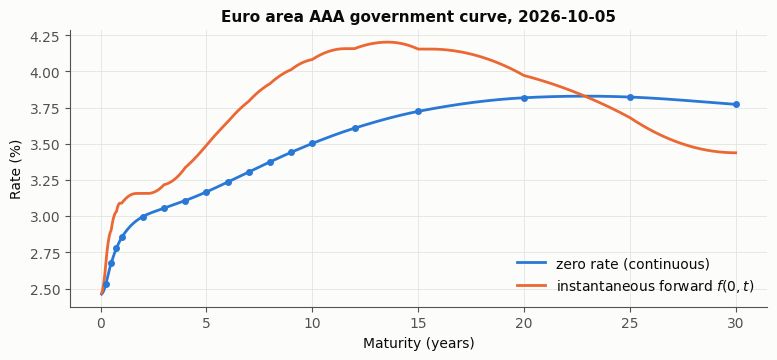

In [2]:
ecb = pd.read_csv(os.path.join("..", "Data", "EUR", "ECB_AAA_YieldCurve.csv"), parse_dates=["Date"]).dropna()
row = ecb.iloc[-1]
VALUATION = row["Date"]
pillars = [c for c in ecb.columns if c.startswith("SR_")]
tenor = lambda c: float(c[3:-1]) / 12 if c.endswith("M") else float(c[3:-1])
curve = YieldCurve([tenor(c) for c in pillars], row[pillars].values.astype(float) / 100,
                   name=f"ECB AAA {VALUATION.date()}")
print(f"Valuation date {VALUATION.date()} | {curve}")

t = np.linspace(0.05, 30, 600)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(t, 100 * curve.zero_rate(t), label="zero rate (continuous)")
ax.plot(t, 100 * curve.instantaneous_forward(t), label="instantaneous forward $f(0,t)$")
ax.plot(curve.times, 100 * curve.zero_rates, "o", color=COLORS[0], ms=4)
ax.set_xlabel("Maturity (years)"); ax.set_ylabel("Rate (%)")
ax.set_title(f"Euro area AAA government curve, {VALUATION.date()}"); ax.legend(); plt.show()

## 2. Hull-White calibration

The call of a 10-year bond with a 3-year call protection is a Bermudan receiver swaption on the co-terminal swaps
(§6.3), so $(a, \sigma)$ are calibrated on the ATM **co-terminal** European receivers $T \times (10 - T)$,
$T = 1, \dots, 5$ (illustrative normal vols, residuals in bp of normal vol).

In [3]:
market = RatePricer(curve, swaption_vols=illustrative_swaption_vols())
swaptions = []
for expiry in [1, 2, 3, 4, 5]:
    atm = market.par_rate(Swaption(expiry, 10 - expiry, 0.0, payer=False, notional=100).underlying())
    swaptions.append(Swaption(expiry, 10 - expiry, atm, payer=False, notional=100))

hw = HullWhite(curve)
calibration = hw.calibrate(market, swaptions)
print(hw, "|", {k: round(v, 3) for k, v in calibration.items() if "bp" in k})

def hw_normal_vol(s):
    return 1e4 * market.implied_swaption_vol(s, hw.price(s))

pd.DataFrame({"swaption": [f"{s.expiry:g}Y x {s.tenor:g}Y" for s in swaptions],
              "ATM strike (%)": [100 * s.strike for s in swaptions],
              "market vol (bp)": [1e4 * market.swaption_vol(s) for s in swaptions],
              "Hull-White vol (bp)": [hw_normal_vol(s) for s in swaptions]}).set_index("swaption")

HullWhite(a=0.0917, sigma=115.4bp) | {'RMSE (bp of normal vol)': 0.746, 'max error (bp)': 1.127}


,ATM strike (%),market vol (bp),Hull-White vol (bp)
swaption,,,
1Y x 9Y,3.60786,78.4,78.8024
2Y x 8Y,3.6685,79.2,78.3125
3Y x 7Y,3.74164,78.8,78.0543
4Y x 6Y,3.82211,77.9,78.0019
5Y x 5Y,3.90142,77,78.1267


## 3. Issuer credit curve

Piecewise constant hazard rates bootstrapped from **illustrative** CDS par spreads of a BBB issuer (quarterly
premiums with accrual on default, $R = 40\%$). Each hazard reprices its CDS exactly.

,CDS spread (bp),hazard rate (%),"survival Q(0,T)",repriced spread (bp)
maturity,,,,
1Y,60,0.996407,0.990085,60
3Y,85,1.63311,0.958269,85
5Y,110,2.53402,0.910914,110
7Y,125,2.8363,0.86068,125
10Y,140,3.1207,0.783759,140


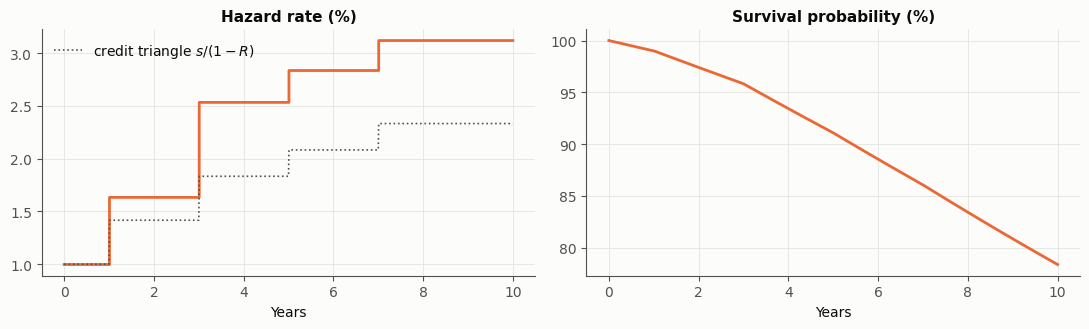

In [4]:
RECOVERY = 0.40
cds_maturities = np.array([1, 3, 5, 7, 10])
cds_spreads = np.array([60, 85, 110, 125, 140]) * 1e-4          # ILLUSTRATIVE
credit = CreditCurve.bootstrap_cds(curve, cds_maturities, cds_spreads, RECOVERY, name="illustrative BBB issuer")

display(pd.DataFrame({"CDS spread (bp)": 1e4 * cds_spreads,
                      "hazard rate (%)": 100 * credit.hazards,
                      "survival Q(0,T)": credit.survival(cds_maturities),
                      "repriced spread (bp)": [1e4 * credit.cds_par_spread(curve, T, RECOVERY) for T in cds_maturities]},
                     index=pd.Index([f"{T}Y" for T in cds_maturities], name="maturity")))

t = np.linspace(0, 10, 1001)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].step(t, 100 * credit.hazard(t), where="post", color=COLORS[1])
axes[0].plot(t, 100 * cds_spreads[np.minimum(np.searchsorted(cds_maturities, t), 4)] / (1 - RECOVERY), ":",
             color=MUTED, lw=1.2, label="credit triangle $s / (1 - R)$")
axes[0].set_title("Hazard rate (%)"); axes[0].set_xlabel("Years"); axes[0].legend()
axes[1].plot(t, 100 * credit.survival(t), color=COLORS[1])
axes[1].set_title("Survival probability (%)"); axes[1].set_xlabel("Years")
plt.tight_layout(); plt.show()

## 4. The bond

10-year bullet bond, 4.50% annual coupon, notional 100, **non-call 3 years**, callable at par:

- **European**: callable on the 3-year coupon date only;
- **Bermudan**: callable on every coupon date from year 3 to year 9;
- **American**: callable at any time from year 3 to maturity, at par + accrued interest.

In [5]:
base = CallableBond(maturity=10, coupon=0.045, notional=100, frequency=1, first_call=3)
bonds = {style: base.with_exercise(style) for style in EXERCISE_STYLES}
for style, bond in bonds.items():
    dates = bond.exercise_dates()
    when = f"from {dates[0]:g}y to {dates[1]:g}y (continuous)" if style == "american" else ", ".join(f"{d:g}y" for d in dates)
    print(f"{style:9s} call dates: {when}")

times, amounts = base.cashflows()
pd.DataFrame({"cash flow": amounts, "risk-free DF": curve.discount(times), "survival": credit.survival(times),
              "callable at par": [f"{'E' if t == 3 else ''}{'B' if 3 <= t < 10 else ''}A" if t >= 3 else ""
                                  for t in times]},
             index=pd.Index(times, name="year"))

european  call dates: 3y
bermudan  call dates: 3y, 4y, 5y, 6y, 7y, 8y, 9y
american  call dates: from 3y to 10y (continuous)


,cash flow,risk-free DF,survival,callable at par
year,,,,
1,4.5,0.971876,0.990085,
2,4.5,0.941819,0.974047,
3,4.5,0.91241,0.958269,EBA
4,4.5,0.883126,0.934292,BA
5,4.5,0.853532,0.910914,BA
6,4.5,0.823582,0.885441,BA
7,4.5,0.793455,0.86068,BA
8,4.5,0.763409,0.834235,BA
9,4.5,0.7337,0.808603,BA


## 5. Prices

Grid: 401 nodes in $x$ ($\pm 6$ standard deviations), at most 1/100 year per step, every coupon and call date on the
grid. The **call option** is worth straight $-$ callable to the issuer. The **OAS** is the constant spread over the
Hull-White short rate that reprices each model price without explicit default (discounting at $r + s$); the Z-spread
is the OAS of the straight bond.

In [6]:
pricer = CallableBondPDE(hw, credit, RECOVERY, n_x=401, steps_per_year=100)

start = time.perf_counter()
straight = pricer.price(base, callable=False)
prices = {"straight": straight, **{style: pricer.price(bond) for style, bond in bonds.items()}}
elapsed = time.perf_counter() - start

risk_free = CallableBondPDE(hw, None)
rows = []
for name, value in prices.items():
    bond = base if name == "straight" else bonds[name]
    callable_ = name != "straight"
    rows.append({"price": value, "call option": straight - value,
                 "default-free price": risk_free.price(bond, callable_),
                 "OAS / Z-spread (bp)": 1e4 * option_adjusted_spread(hw, bond, value, callable_)})
results = pd.DataFrame(rows, index=pd.Index(list(prices), name="bond"))
print(f"4 PDE solves in {elapsed:.2f}s")
results

4 PDE solves in 1.65s


,price,call option,default-free price,OAS / Z-spread (bp)
bond,,,,
straight,96.4236,0,108.171,138.985
european,95.5589,0.864706,102.593,130.836
bermudan,95.0605,1.36312,101.971,127.885
american,94.9495,1.47411,101.828,127.45


**Reading the table.**

- **European ≥ Bermudan ≥ American.** More call dates give the issuer more choice, so the option is worth more and
  the bond less. Most of the value comes from the first call date: the Bermudan adds the right to wait, and the
  American only adds the intermediate dates.
- **Credit lowers the option value.** With default risk, the bond is worth less, so it is further below par and the
  call is less likely to be in the money (the issuer calls when its own refinancing is cheap, i.e. when rates
  *and* its spread are low). The option is much more valuable on the default-free bond.
- **OAS < Z-spread.** The OAS strips out the call option: the Z-spread of a callable bond mixes credit and
  optionality, the OAS is the spread of the credit risk alone given the volatility model.

## 6. Validation

### 6.1 Straight bond: PDE vs closed form

Default independent of rates gives $\sum_i c_i P(0,t_i) Q(0,t_i) + R N \int_0^T P(0,t)\,(-dQ(0,t))$.

In [7]:
rows = []
for label, cr, R in [("default-free", None, 0.0), ("credit, R = 0", credit, 0.0), ("credit, R = 40%", credit, RECOVERY)]:
    pde = CallableBondPDE(hw, cr, R).price(base, callable=False)
    exact = straight_bond_value(curve, base, cr, R)
    rows.append({"case": label, "PDE": pde, "closed form": exact, "difference": pde - exact})
pd.DataFrame(rows).set_index("case")

,PDE,closed form,difference
case,,,
default-free,108.171,108.171,2.65196e-07
"credit, R = 0",89.1992,89.1992,2.1408e-07
"credit, R = 40%",96.4236,96.4236,1.79448e-07


### 6.2 European call: PDE vs Jamshidian

- **Default-free**: a bond callable at par on a coupon date is the straight bond minus a **European receiver
  swaption** (receive the coupon on the remaining swap), priced in closed form by `HullWhite` (Jamshidian).
- **Zero recovery**: the call is an option on the risky coupon bond $\sum c_i Q(t_i)/Q(T_0) P(T_0, t_i)$, held only
  if the issuer survives to $T_0$; Jamshidian's decomposition still applies.

In [8]:
euro = bonds["european"]
receiver = Swaption(euro.first_call, euro.maturity - euro.first_call, euro.coupon, payer=False, notional=100)
rows = [{"case": "default-free", "PDE": CallableBondPDE(hw, None).price(euro),
         "closed form": straight_bond_value(curve, euro) - hw.price(receiver)},
        {"case": "credit, R = 0", "PDE": CallableBondPDE(hw, credit, 0.0).price(euro),
         "closed form": european_callable_zero_recovery(hw, euro, credit)[0]}]
table = pd.DataFrame(rows).set_index("case")
table["difference"] = table["PDE"] - table["closed form"]
table

,PDE,closed form,difference
case,,,
default-free,102.593,102.593,-0.000118625
"credit, R = 0",89.0505,89.0505,-4.5552e-05


### 6.3 Bermudan call: PDE vs Longstaff-Schwartz

Default-free, the Bermudan callable bond is the straight bond minus a **Bermudan receiver swaption** of expiry 3Y
on the co-terminal swaps, priced independently by Monte Carlo + Longstaff-Schwartz (`HullWhite.bermudan_swaption`,
exact simulation, 400,000 paths).

In [9]:
berm = bonds["bermudan"]
bermudan_receiver = Swaption(berm.first_call, berm.maturity - berm.first_call, berm.coupon, payer=False,
                             notional=100, exercise="bermudan")
lsm = hw.bermudan_swaption(bermudan_receiver, n_paths=400_000, seed=7)
pde = CallableBondPDE(hw, None).price(berm)
mc = straight_bond_value(curve, berm) - lsm["price"]
print(f"PDE {pde:.4f} | Longstaff-Schwartz {mc:.4f} +/- {1.96 * lsm['stderr']:.4f} (95%) | "
      f"difference {(pde - mc) / lsm['stderr']:+.2f} standard errors")
pd.Series(lsm["exercise probability"], name="probability of exercise (default-free)").to_frame().T

PDE 101.9708 | Longstaff-Schwartz 101.9743 +/- 0.0112 (95%) | difference -0.61 standard errors


,3,4,5,6,7,8,9
probability of exercise (default-free),0.474158,0.09071,0.055915,0.042735,0.0354925,0.03293,0.03239


### 6.4 From Bermudan to American

A Bermudan bond callable every $1/m$ year from year 3 must converge to the American bond as $m \to \infty$ (the
American is the limit of continuous call dates). Callable on more dates, the bond is worth less.

In [10]:
rows = []
for m, label in [(1, "annual"), (2, "semi-annual"), (4, "quarterly"), (12, "monthly"), (52, "weekly")]:
    rows.append({"call dates": label, "price": pricer.price(bonds["bermudan"].with_call_frequency(m))})
rows.append({"call dates": "American (continuous)", "price": prices["american"]})
pd.DataFrame(rows).set_index("call dates")

,price
call dates,
annual,95.0605
semi-annual,95.0061
quarterly,94.9777
monthly,94.9585
weekly,94.9523
American (continuous),94.9495


### 6.5 Grid convergence

Crank-Nicolson is second order in $x$ and $t$ for the straight and European bonds; the American converges more
slowly (first order in $t$ near the exercise boundary, as for any projected scheme).

In [11]:
rows = []
for n_x, spy in [(101, 25), (201, 50), (401, 100), (801, 200), (1601, 400)]:
    p = CallableBondPDE(hw, credit, RECOVERY, n_x=n_x, steps_per_year=spy)
    rows.append({"nodes x": n_x, "steps / year": spy, **{style: p.price(bond) for style, bond in bonds.items()}})
conv = pd.DataFrame(rows).set_index(["nodes x", "steps / year"])
display(conv)
print("Error vs the finest grid (bp of notional):")
(1e2 * (conv - conv.iloc[-1])).iloc[:-1]

,,european,bermudan,american
nodes x,steps / year,,,
101,25,95.5605,95.0602,94.9529
201,50,95.5588,95.0602,94.951
401,100,95.5589,95.0605,94.9495
801,200,95.5591,95.0604,94.949
1601,400,95.559,95.0605,94.9487


Error vs the finest grid (bp of notional):


,,european,bermudan,american
nodes x,steps / year,,,
101,25,0.147637,-0.0230829,0.425472
201,50,-0.0195109,-0.022569,0.229636
401,100,-0.0119281,0.00418806,0.084661
801,200,0.00295141,-0.0025956,0.0300437


## 7. When does the issuer call?

The issuer calls when rates are **low**: on each call date $t$, below a critical short rate $r^*(t)$ the bond is
worth more than the call price. For the American bond, $r^*(t)$ is a continuous **exercise boundary**; it rises
toward maturity (fewer coupons left to save, so a smaller rate drop suffices). The fewer future call dates the
issuer keeps, the less it gains by waiting: the Bermudan threshold is **above** the American boundary, and the
European one (last and only chance) is the highest. With more call dates, the issuer waits for lower rates.

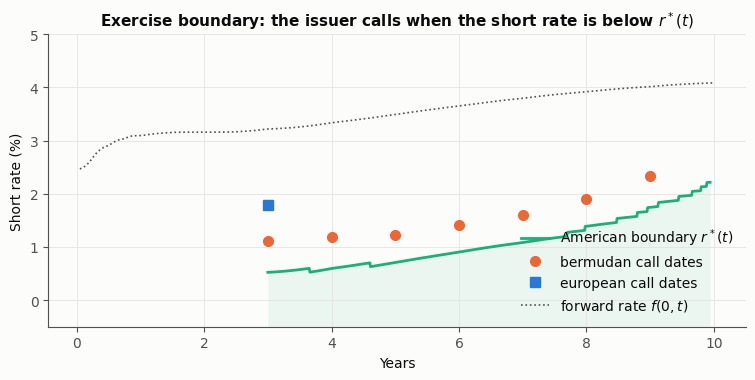

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.8))
t_am, r_am = pricer.short_rate_boundary(bonds["american"])
t_am, r_am = t_am[t_am < 9.95], r_am[t_am < 9.95]        # last days : called almost surely, boundary at the grid edge
ax.plot(t_am, 100 * r_am, color=STYLE_COLOR["american"], label="American boundary $r^*(t)$")
for style, marker in [("bermudan", "o"), ("european", "s")]:
    t_b, r_b = pricer.short_rate_boundary(bonds[style])
    ax.plot(t_b, 100 * r_b, marker, color=STYLE_COLOR[style], ms=7, label=f"{style} call dates")
tt = np.linspace(0.05, 10, 400)
ax.plot(tt, 100 * curve.instantaneous_forward(tt), ":", color=MUTED, lw=1.2, label="forward rate $f(0,t)$")
ax.fill_between(t_am, -1, 100 * r_am, color=STYLE_COLOR["american"], alpha=0.07, lw=0)
ax.set_ylim(min(-0.5, 100 * np.nanmin(r_am) - 0.5), 5)
ax.set_xlabel("Years"); ax.set_ylabel("Short rate (%)")
ax.set_title("Exercise boundary: the issuer calls when the short rate is below $r^*(t)$"); ax.legend(loc="lower right")
plt.show()

The PDE gives the price for every initial short rate at once ($V(0, x)$ on the grid). The callable bond is
**capped**: when rates fall, the straight bond keeps rising while the callable bond is pinned near the call price
(negative convexity). The American cap binds earliest.

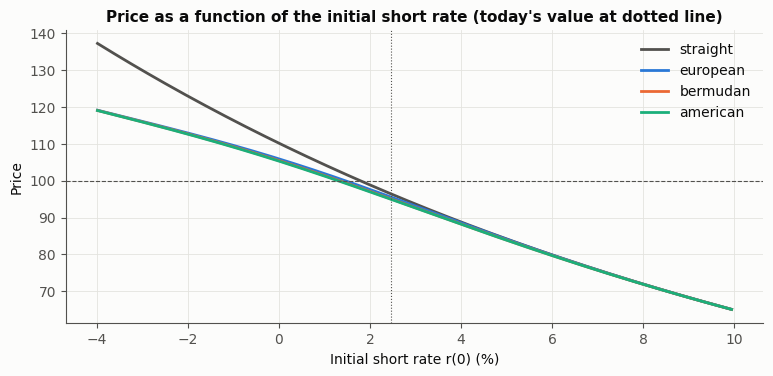

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.8))
sol = pricer.solve(base, callable=False)
mask = (sol["short rate"] > -0.04) & (sol["short rate"] < 0.10)
ax.plot(100 * sol["short rate"][mask], sol["values"][mask], color=STYLE_COLOR["straight"], label="straight")
for style, bond in bonds.items():
    sol = pricer.solve(bond)
    ax.plot(100 * sol["short rate"][mask], sol["values"][mask], color=STYLE_COLOR[style], label=style)
ax.axhline(100, color=MUTED, lw=0.8, ls="--")
ax.axvline(100 * sol["short rate"][pricer.n_x // 2], color=MUTED, lw=0.8, ls=":")
ax.set_xlabel("Initial short rate r(0) (%)"); ax.set_ylabel("Price")
ax.set_title("Price as a function of the initial short rate (today's value at dotted line)"); ax.legend()
plt.show()

## 8. Interest rate risk

Parallel shifts of the risk-free curve, Hull-White refitted to each shifted curve ($a$, $\sigma$ unchanged).
Effective duration and convexity use $\pm 10$bp; vega is per 1bp of $\sigma$ and CS01 per 1bp of hazard rate.

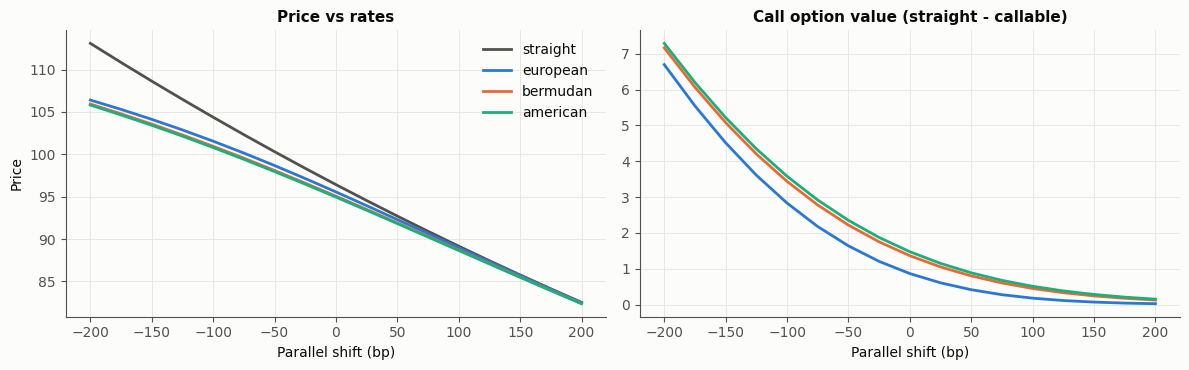

,price,effective duration,effective convexity,DV01,vega (per bp of sigma),CS01
straight,96.4236,7.88761,71.5621,0.0760552,8.41879e-09,-0.0449381
european,95.5589,6.71424,-61.1311,0.0641605,-0.0172222,-0.0375958
bermudan,95.0605,6.5364,-51.1506,0.0621353,-0.0244361,-0.0361614
american,94.9495,6.49249,-47.3423,0.0616459,-0.0258426,-0.0358538


In [14]:
shifts = np.arange(-200, 201, 25)
scenario = {name: [] for name in ["straight", *EXERCISE_STYLES]}
for bp in shifts:
    p = pricer.with_model(hw.with_curve(curve.shifted(bp)))
    scenario["straight"].append(p.price(base, callable=False))
    for style, bond in bonds.items():
        scenario[style].append(p.price(bond))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, values in scenario.items():
    axes[0].plot(shifts, values, color=STYLE_COLOR[name], label=name)
    if name != "straight":
        axes[1].plot(shifts, np.array(scenario["straight"]) - np.array(values), color=STYLE_COLOR[name])
axes[0].set_xlabel("Parallel shift (bp)"); axes[0].set_ylabel("Price"); axes[0].set_title("Price vs rates"); axes[0].legend()
axes[1].set_xlabel("Parallel shift (bp)"); axes[1].set_title("Call option value (straight - callable)")
plt.tight_layout(); plt.show()

risk = {"straight": effective_risk(pricer, base, callable=False),
        **{style: effective_risk(pricer, bond) for style, bond in bonds.items()}}
pd.DataFrame(risk).T

The straight bond has a positive convexity; the callable bonds have a **negative** effective convexity and a shorter
duration (when rates fall the expected life shortens). Vega is negative: the bondholder is short the call. The
CS01 is smaller in absolute value for callable bonds: a wider spread pushes the call out of the money, which
partially offsets the loss.

## 9. Volatility and credit

The call option value increases with $\sigma$ (the issuer's option gains from rate dispersion). A credit
deterioration makes the call less likely: the three callable bonds converge to the straight bond.

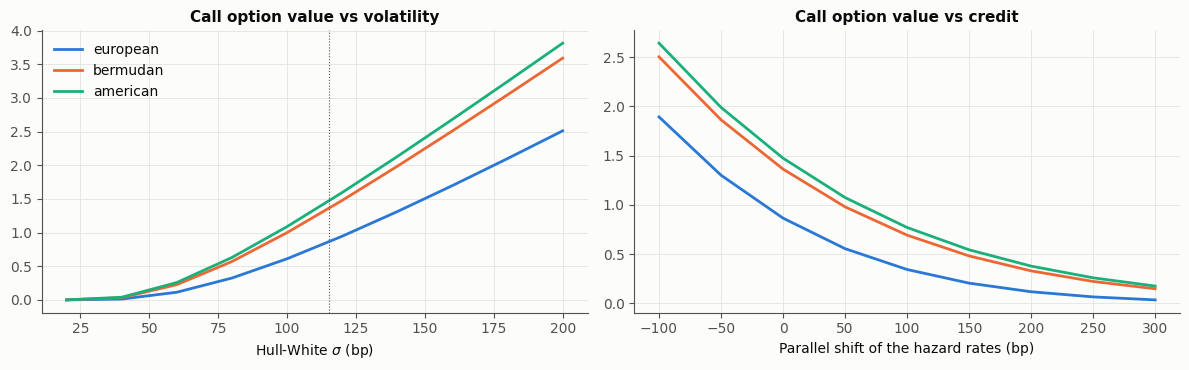

In [15]:
sigmas = np.linspace(0.002, 0.020, 10)
hazard_shifts = np.arange(-100, 301, 50)
vol_scan = {style: [pricer.with_model(hw.with_vol_shift(s - hw.sigma)).price(bond) for s in sigmas]
            for style, bond in bonds.items()}
credit_scan = {"straight": [pricer.with_credit(credit.shifted(bp)).price(base, callable=False) for bp in hazard_shifts],
               **{style: [pricer.with_credit(credit.shifted(bp)).price(bond) for bp in hazard_shifts]
                  for style, bond in bonds.items()}}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
straight_vol = pricer.price(base, callable=False)
for style, values in vol_scan.items():
    axes[0].plot(1e4 * sigmas, straight_vol - np.array(values), color=STYLE_COLOR[style], label=style)
axes[0].axvline(1e4 * hw.sigma, color=MUTED, lw=0.8, ls=":")
axes[0].set_xlabel(r"Hull-White $\sigma$ (bp)"); axes[0].set_title("Call option value vs volatility"); axes[0].legend()
for style in EXERCISE_STYLES:
    axes[1].plot(hazard_shifts, np.array(credit_scan["straight"]) - np.array(credit_scan[style]),
                 color=STYLE_COLOR[style], label=style)
axes[1].set_xlabel("Parallel shift of the hazard rates (bp)"); axes[1].set_title("Call option value vs credit")
plt.tight_layout(); plt.show()

## 10. Step-down call schedule

Callable bonds often have a **call premium** decreasing over time, e.g. 102 from year 3, 101 from year 5, par from
year 7. The premium makes early calls more expensive and lowers the option value, more so for the European bond,
whose only call date is at 102.

In [16]:
step_down = {3: 102.0, 5: 101.0, 7: 100.0}
rows = []
for style, bond in bonds.items():
    sd = bond.with_call_schedule(step_down)
    rows.append({"style": style, "par call": prices[style], "step-down 102/101/100": pricer.price(sd),
                 "option (par)": straight - prices[style], "option (step-down)": straight - pricer.price(sd)})
pd.DataFrame(rows).set_index("style")

,par call,step-down 102/101/100,option (par),option (step-down)
style,,,,
european,95.5589,95.8716,0.864706,0.551973
bermudan,95.0605,95.3617,1.36312,1.06193
american,94.9495,95.2783,1.47411,1.14528


## 11. OAS from a quoted price

In practice the bond price is observed and the OAS is solved for. For a quoted price of **95.00**, the OAS
differs across call styles (the more call dates, the more of the yield comes from the short option, the lower the
OAS) and depends on the volatility assumption: a higher $\sigma$ makes the option worth more and the OAS lower.

In [17]:
QUOTE = 95.0
rows = []
for s in [0.006, hw.sigma, 0.016]:
    model = hw.with_vol_shift(s - hw.sigma)
    rows.append({"sigma (bp)": round(1e4 * s, 1),
                 "Z-spread straight (bp)": 1e4 * option_adjusted_spread(model, base, QUOTE, callable=False),
                 **{f"OAS {style} (bp)": 1e4 * option_adjusted_spread(model, bond, QUOTE) for style, bond in bonds.items()}})
pd.DataFrame(rows).set_index("sigma (bp)")

,Z-spread straight (bp),OAS european (bp),OAS bermudan (bp),OAS american (bp)
sigma (bp),,,,
60,157.112,154.489,151.657,150.998
115.4,157.112,139.878,128.898,126.596
160,157.112,123.219,105.302,101.629


## 12. Summary and limitations

- One PDE pricer handles the three call styles: only the set of dates where $V \leftarrow \min(V, K + AI)$ is applied
  changes. It reprices the straight bond and the European call in closed form (Jamshidian, with and without
  default) and the Bermudan call within Monte Carlo error (Longstaff-Schwartz), and the Bermudan converges to the
  American as call dates get denser.
- **Limitations.** Default intensity is deterministic and independent of rates: a stochastic, correlated
  intensity (e.g. CIR or a second Gaussian factor) would let the issuer also call when its *own spread* tightens.
  One rate factor cannot decorrelate the rates of different maturities. Times are year fractions (no day count,
  calendar or call notice period). The volatilities and the CDS spreads are illustrative.